# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())   # Cantidad de valores nulos
print(users.isna().mean())  # Proporción de valores nulos

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
print(usage.isna().sum())   # Cantidad de valores nulos
print(usage.isna().mean())  # Proporción de valores nulos

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
   
- Indica qué harías: ¿imputar, eliminar, ignorar?

  **Users**

•	**city:** 469 nulos → 11.7% de proporción. Es una zona media, pero como es una columna categórica y no numérica no se puede imputar, tampoco es opción eliminar 469 filas. Se debe rellenar con el texto “Unknown” para conservar la información valida de esas filas, dejar explicito que no se sabe la ciudad y si luego se agrupa o se analiza por cuidad “Unknown” aparecerá con su propia categoría, sin mezclarse ni ensuciar los datos de las cuidades reales. 

•	**churn_date:** 3534 nulos → 88.3% de proporción. Cómo tiene más del 80% se ignora o se elimina, pero es importante saber el cliente cuando cancela el servicio. En este caso se crearía una columna nueva booleana que sea True/False que indique si churn_date está vacío o no.
-Si churn_date es nulo → el cliente sigue activo (is_active = True).
-Si churn_date tiene una fecha → el cliente canceló (is_active = False).
La columna original churn_date se deja tal cual, con sus nulos, porque el nulo significa algo real, no un error.

**Usage** 

•	**duration:** 22076 nulos → 55.2%.   Los nulos no son errores. Una llamada no tiene "longitud de texto" y un mensaje no tiene "duración". Se debe dejar los nulos tal cual, porque no representan datos faltantes, sino que indican “esta métrica no aplica a ese tipo de uso”. No se deben imputar ni eliminar esas filas.

•	**length:** 17896 nulos → 44.7%. Esta columna tiene relación con duration, también se debe dejar los nulos tal cual, sin imputar ni eliminar filas.

•	**date:** 50 nulos → 0.125%. La columna es tipo fecha se debe dejar como nulo “NaN”. Muy bajo porcentaje. 


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [17]:
# cantidad de valores invalidos de age 
print((users['age'] == -999).sum())

55


In [18]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` se ven consistentes, rangos continuos, sin negativos, sin ceros sospechosos.
- Las columnas `duration` y `length` la columna duration si tiene sentido el 0 en min, puede ser llamada no contestada o corta y en la columna length el min 0      posible pero raro; se puede revisar, no necesariamente un error y en max si es razonable 1490 puede ser un mensaje largo. 

In [19]:
# explorar columnas categóricas de users
columnas_user = users[['city', 'plan']].describe(include='object')
columnas_user

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna `city` tiene count = 3531, es decir, menos que el total de filas. confirma los 469 nulos. 4000 - 469 = 3531
- La columna `plan` tiene count = 4000, lo que significa que no tiene nulos. 2 valores únicos (unique = 2), siendo "Basico" el más frecuente (top), apareciendo     2595 veces (freq).

In [20]:
# explorar columna categórica de usage
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` indica si el registro es un mensaje de texto (22092 - 55.2%) o una llamada (17908 - 44.7%). Estos porcentajes coinciden exactamente con los nulos encontrados en length (55.2%) y duration (44.7%), confirmando que son nulos estructurales: una llamada no tiene length y un mensaje no tiene duration



---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

- La columna age tiene un sentinel claro: -999, que no es una edad razonable. La acción recomendada es convertir esos valores a NaN antes de cualquier análisis estadístico, para que no distorsionen la media ni la desviación estándar

- La columna city: "?" covertirlo a nulo.

- La columna reg_date: fechas de 2026 covertirlo a NaT

- La columna date: NaT que ya existian, se deben de dejar asi. 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [21]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors="coerce") 

In [22]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors="coerce") 

In [23]:
# Revisar los años presentes en `reg_date` de users
users["reg_date"].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`, la mayoría en 2022-2024, pero 40 filas con el año imposible 2026. Estas 40 filas se dejarian pero serian excluidas 
puntualmente de los análisis por año.

In [24]:
# Revisar los años presentes en `date` de usage
usage["date"].dt.year.value_counts(dropna=False)

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, 39950 registros válidos en 2024, y 50 filas con NaT (fechas que no se pudieron convertir, probablemente por formato inválido o vacío).

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

En `reg_date`, se encontró que la mayoría son en 2022-2024, pero 40 filas con el año imposible 2026. Estas 40 filas se dejarían, pero serian excluidas puntualmente de los análisis por año. El dato es irrecuperable (no se puede "adivinar" la fecha real). Al hacer agregaciones por año hay que filtrarlas o tratarlas con cuidado.

En `date`, se encontró que hay 39950 registros válidos en 2024, y 50 filas con NaT (fechas que no se pudieron convertir, probablemente por formato inválido o vacío).
Son pocas filas sobre el total, no se pueden recuperar, y afectarían el análisis de tendencias por año si se dejan sin marcar. Deben ser excluidas en esos análisis (pero sin borrar los registros completos, ya que otras columnas como duration o type siguen siendo válidas).


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [25]:
# Reemplazar -999 por la mediana de age
users['age'] = users['age'].replace([-999], pd.NA)
age_mediana = users["age"].median()
users['age'] = users['age'].fillna(age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [26]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace(["?"], pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [27]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].describe()

count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [28]:
# Verificación MAR en usage (Missing At Random) para duration
usage[usage['duration'].isna()]['type'].value_counts()

text    22076
Name: type, dtype: int64

In [29]:
# Verificación MAR en usage (Missing At Random) para length
usage[usage['length'].isna()]['type'].value_counts()

call    17896
Name: type, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Son MAR porque la ausencia no es completamente al azar, sino que depende de otra variable observada (type), y no del propio valor faltante. A diferencia de MCAR que es completamente al azar, sin relación con nada o MNAR donde la ausencia depende del propio valor que falta.

•	duration nulo ⟶ siempre que type == 'text'
•	length nulo ⟶ siempre que type == 'call'

Una llamada no tiene "longitud de texto" y un mensaje no tiene "duración de llamada", así que los nulos reflejan una estructura real de los datos, no datos faltantes por error.

Se dejan como nulos.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [30]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id")\
            .agg({'is_text':'sum','is_call':'sum','duration':'sum'})\
            .reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [31]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text":"cant_mensajes","is_call":"cant_llamadas","duration":"cant_minutos_llamada"})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [32]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id",how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [33]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes','cant_llamadas','cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [34]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

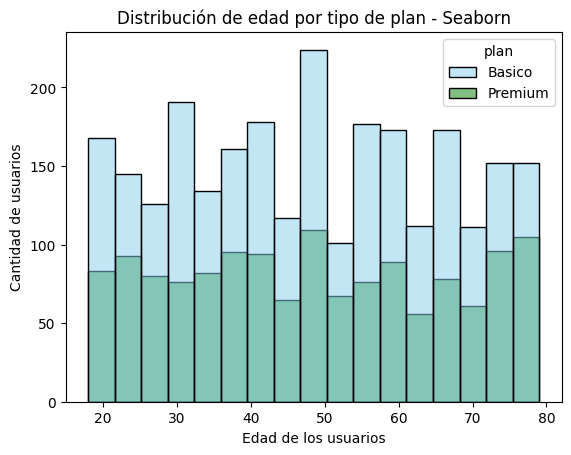

In [35]:

# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue','green'])
plt.xlabel('Edad de los usuarios')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de edad por tipo de plan - Seaborn')
plt.show()


💡**Insights:** Oportunidad de conversión del plan Básico al Premium.
-En general, el plan Básico predomina en casi todos los rangos de edad. Esto representa una oportunidad para investigar qué características o beneficios podrían incentivar a estos usuarios a cambiarse al plan Premium.

**Acción recomendada:** 
-Segmentar a los usuarios del plan Básico por grupos de edad.
-Identificar qué beneficios valoran más los usuarios Premium.
-Diseñar campañas personalizadas que destaquen los beneficios del plan Premium.
-Medir la tasa de conversión de Básico a Premium por grupo de edad.

- **Distribución:** los usuarios tienen edades aproximadamente entre los 18 y los 80 años. los datos no presentan una forma de campana (simétrica), sino que muestran varias concentraciones de usuarios en diferentes intervalos de edad. hay variaciones en la cantidad de usuarios entre los distintos rangos. Se observan concentraciones importantes alrededor de los 30, 40 y 50 años. En general, el plan Básico predomina en casi todos los rangos de edad, lo cual es coherente con la proporción global (65% Básico / 35% Premium). Sin embargo, en el rango de 50-55 años, la diferencia se reduce notablemente, acercándose a una proporción más pareja entre ambos planes.

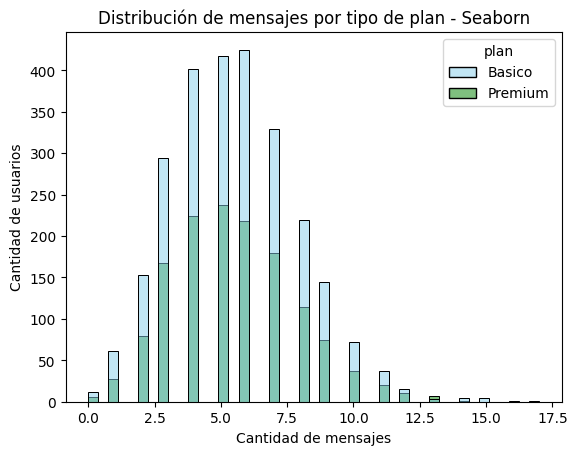

In [36]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue','green'])
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de mensajes por tipo de plan - Seaborn')
plt.show()

💡**Insights:** Oportunidad de fidelización y conversión de usuarios activos.
-El gráfico muestra que existe una concentración importante de usuarios que envían entre 3 y 7 mensajes. También hay un grupo reducido que supera los 10 mensajes.

**Acción recomendada:**
-Identificar a los usuarios que envían más de 10 mensajes para conocer sus necesidades y evaluar si podrían beneficiarse de un plan Premium.
-Analizar qué características utilizan los usuarios más activos para identificar oportunidades de mejora del servicio.
-Diseñar estrategias de conversión para usuarios Básicos con niveles elevados de actividad.
-Implementar acciones de fidelización para mantener activos a los usuarios que utilizan frecuentemente la plataforma.

- **Distribución:** (sesgada a la derecha) La mayor concentración de usuarios se encuentra entre 3 y 7 mensajes. A medida que aumenta el número de mensajes, la frecuencia disminuye y aparece una cola hacia la derecha. El intervalo de 5 a 6 mensajes presenta las frecuencias más altas. Existen pocos usuarios que envían más de 12 mensajes, llegando aproximadamente a 17. el plan Básico presenta una mayor cantidad de usuarios que el Premium en la mayoría de los intervalos. Significa que la mayoría de los usuarios envía una cantidad moderada de mensajes, mientras que existe un grupo pequeño que utiliza el servicio con mucha mayor frecuencia. 

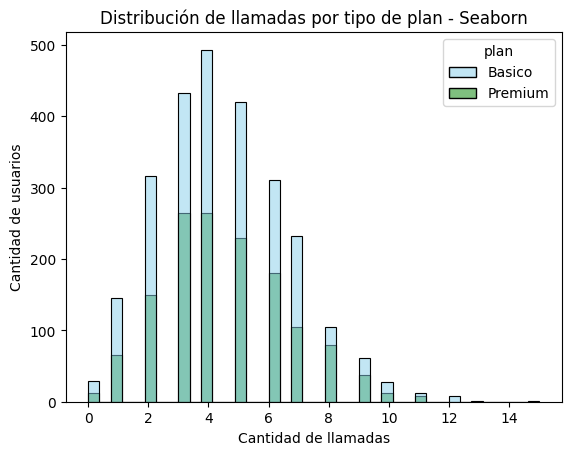

In [37]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue','green'])
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de llamadas por tipo de plan - Seaborn')
plt.show()

💡**Insights:** Identificar usuarios con alta demanda de llamadas para impulsar la conversión a Premium.
-El gráfico muestra que la mayoría de los usuarios realiza entre 3 y 6 llamadas, pero existe un grupo reducido que supera las 9 llamadas.

**Acción recomendada:**
-Identificar a los usuarios Básicos que realizan más de 9 llamadas.
-Analizar si estos usuarios están cerca de los límites de consumo de su plan.
-Comunicar los beneficios del plan Premium a los usuarios que presentan mayor actividad.
-Diseñar estrategias de fidelización para los usuarios que utilizan frecuentemente el servicio.

- **Distribución:** (sesgada a la derecha) La mayor concentración de usuarios se encuentra entre 3 y 6 llamadas. A medida que aumenta el número de llamadas, la cantidad de usuarios disminuye. El punto más alto se encuentra alrededor de las 4 llamadas, lo que indica que es uno de los valores más frecuentes. Hay pocos usuarios que realizan más de 9 llamadas, y algunos alcanzan aproximadamente 13 llamadas. El plan Básico presenta una mayor frecuencia de usuarios que el Premium en prácticamente todos los valores de llamadas. Significa que la mayoría de los usuarios realiza una cantidad moderada de llamadas, mientras que existe un grupo pequeño que utiliza el servicio con mayor intensidad.

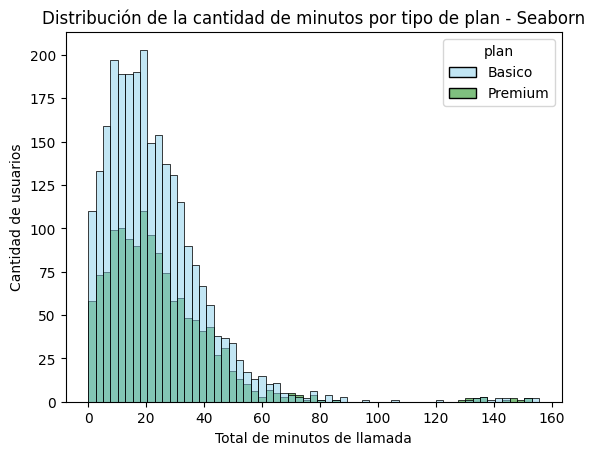

In [38]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue','green'])
plt.xlabel('Total de minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de la cantidad de minutos por tipo de plan - Seaborn')
plt.show()


💡**Insights:** Identificar usuarios con alto consumo de minutos para desarrollar estrategias de conversión y fidelización.
-El histograma muestra que la mayoría de los usuarios tiene un consumo relativamente bajo, pero existe un grupo reducido con consumos superiores a 100 minutos.

**Acción recomendada:**
-Identificar a los usuarios Básicos que presentan consumos elevados de minutos.
-Evaluar si los beneficios del plan Premium responden mejor a sus necesidades.
-Diseñar campañas de comunicación dirigidas a usuarios con mayor consumo.
-Analizar si los usuarios Premium mantienen un mayor nivel de utilización del servicio a lo largo del tiempo.

- **Distribución:** La mayor concentración de usuarios se encuentra en los rangos bajos de consumo, mientras que la frecuencia disminuye a medida que aumentan los minutos. Existen pocos usuarios con consumos elevados, algunos superan los 100 minutos y llegan aproximadamente a 155 minutos. El plan Básico presenta una mayor frecuencia de usuarios en la mayoría de los intervalos. Sin embargo, ambos planes muestran un comportamiento general similar. Significa que la mayoría de los usuarios tiene un consumo moderado de minutos, mientras que existe un grupo pequeño que utiliza el servicio durante períodos considerablemente más largos.


### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

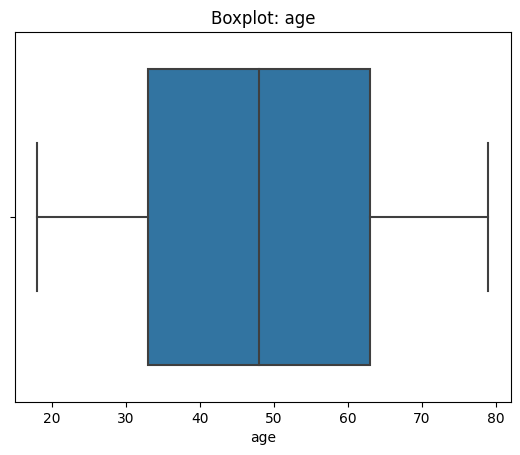

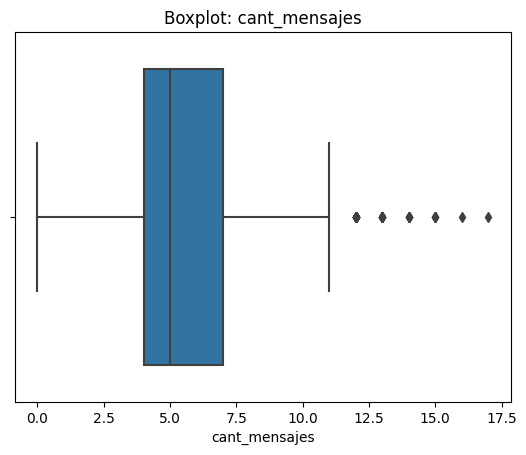

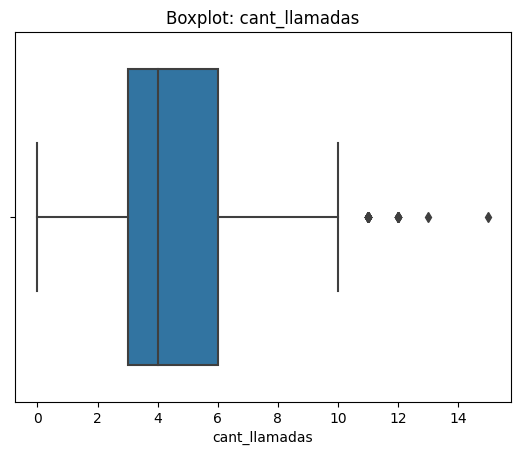

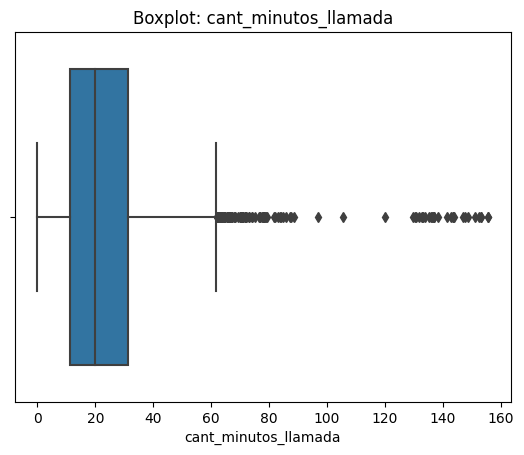

In [39]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']


for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()

💡**Insights:** 

- **Age:**(No presenta outliers). No hay puntos fuera de los bigotes, lo que indica que no hay outliers en esta variable. Los datos de edad están bien distribuidos dentro de un rango razonable (18-79 aprox), sin valores extremos que llamen la atención.

- **cant_mensajes:**(Presenta outliers). Sí, existen valores atípicos en la parte superior del gráfico. La mayoría de los usuarios envía una cantidad relativamente moderada de mensajes, concentrándose entre 4 y 7. Hay un grupo pequeño de usuarios que envía entre 12 y 17 mensajes. Estos valores se encuentran fuera del límite superior del bigote y se identifican como posibles outliers. Esto no significa que sean datos incorrectos. Podrían representar usuarios que utilizan el servicio con mayor frecuencia que el resto.

  
- **cant_llamadas:**(Presenta outliers). Sí, existen valores atípicos en el extremo superior del gráfico. La mayoría de los usuarios realiza entre 3 y 6 llamadas, pero existe un grupo pequeño que realiza entre 11 y 15 llamadas. Estos usuarios presentan un comportamiento diferente al de la mayoría, porque utilizan el servicio con mayor frecuencia. No significa que los datos sean incorrectos; podrían ser usuarios con necesidades de comunicación más elevadas.

  
- **cant_minutos_llamada:**(Presenta outliers). Sí, existen numerosos valores atípicos en el extremo superior del gráfico. La mayoría de los usuarios consume una cantidad relativamente moderada de minutos, concentrándose entre 11 y 31 minutos. Sin embargo, existe un grupo de usuarios que consume más de 62 minutos, llegando algunos a superar los 150 minutos. Estos usuarios presentan un comportamiento de consumo considerablemente superior al de la mayoría. Podrían representar clientes que utilizan intensivamente el servicio.

In [40]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites: 
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR

    print(f"Límite superior de {col}: {limite_superior}")

Límite superior de cant_mensajes: 11.5
Límite superior de cant_llamadas: 10.5
Límite superior de cant_minutos_llamada: 61.8575


In [41]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 

- **cant_mensajes:** Se deben mantener porque estos valores podrían representar usuarios que utilizan con mayor frecuencia el servicio. No hay evidencia de que sean errores de registro. Estos usuarios pueden ser importantes para identificar clientes activos y desarrollar estrategias de fidelización o conversión al plan Premium.

*Límite superior: 11.5 mensajes.
*Valor máximo: 17 mensajes.
*Se identifican usuarios que envían más de 11 mensajes.


- **cant_llamadas:** Se deben mantener porque podrían representar usuarios con necesidades de comunicación superiores al promedio. Eliminar estos registros podría significar perder información relevante sobre los clientes que utilizan más intensivamente el servicio.

*Límite superior: 10.5 llamadas.
*Valor máximo: 15 llamadas.
*Se identifican usuarios que realizan 11 o más llamadas.

- **cant_minutos_llamada:** Se deben mantener porque estos valores podrían representar usuarios que realizan llamadas de mayor duración o tienen necesidades de comunicación más elevadas. Aunque existen bastantes valores atípicos, no significa que sean incorrectos. Eliminarlos podría distorsionar el comportamiento real de consumo de los usuarios. Seria importante investigar si los usuarios con mayor consumo de minutos pertenecen al plan Básico o Premium.

*Límite superior: 61.8575 minutos.
*Valor máximo: 155.69 minutos.
*Se observan numerosos usuarios que superan el límite superior.
  

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [42]:

# Crear columna grupo_uso

def clasificar(uso): 
    if uso['cant_llamadas'] < 5 and uso['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif uso['cant_llamadas'] < 10 and uso['cant_mensajes'] < 10:
        return 'Uso medio'
    else: 
        return 'Alto uso' 
        

user_profile['grupo_uso'] = user_profile[['cant_llamadas', 'cant_mensajes']].apply(clasificar, axis=1)


In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [44]:
# Crear columna grupo_edad

def clasificar(age): 
    if age < 30:
        return 'Joven'
    elif age < 60:
        return 'Adulto'
    else: 
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile['age'].apply(clasificar)

In [45]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

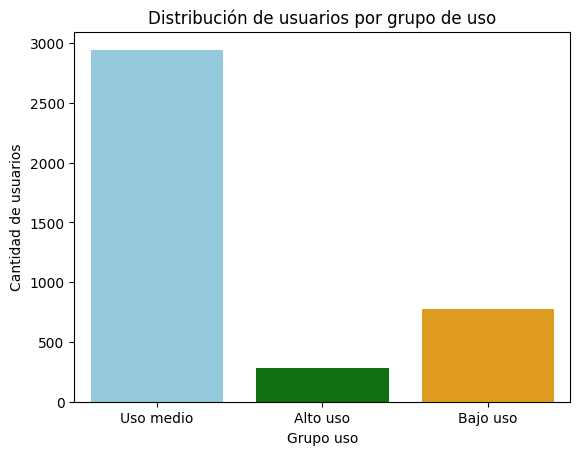

In [46]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', palette=['skyblue','green','orange'])
plt.xlabel('Grupo uso')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios por grupo de uso')
plt.show()

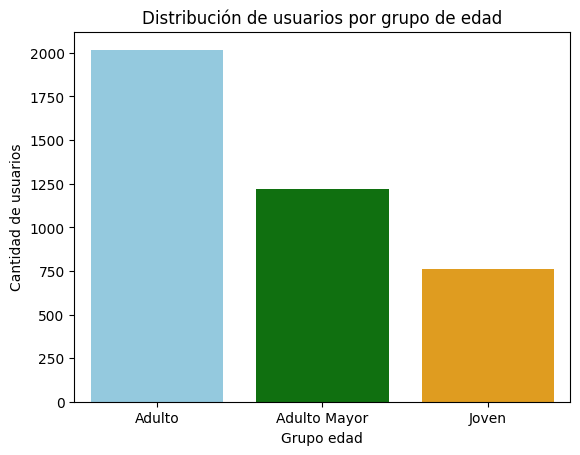

In [47]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', palette=['skyblue','green','orange'])
plt.xlabel('Grupo edad')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios por grupo de edad')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- Los problemas originales en los datos fueron:

  - **Columna age:** -999. La cantidad de valores eran 55
  
  - **Columna city:** "?". La cantidad de valores eran 96 (separado de los 469 nulos que ya existían)
  
  - **Columna reg_date:** fechas de 2026. La cantidad eran 40
    
  - **Columna date:** NaT (ya existentes). La cantidad eran 50

- La limpieza permitió corregir valores inválidos, conservar información útil y evitar que los errores distorsionaran los resultados. Es importante destacar que no todos los valores nulos representan errores, algunos tienen una explicación propia del funcionamiento del servicio.
    

🔍 **Segmentos por Edad**

Son tres grupos:

Segmento	Rango de edad

Joven	Menores de 30 años
Adulto	Entre 30 y 59 años
Adulto mayor	60 años o más

A partir de los histogramas podemos observar que:

Los usuarios tienen edades aproximadamente entre 18 y 79 años. No existe una distribución normal claramente definida. Se observan concentraciones de usuarios en diferentes rangos, especialmente alrededor de los 30, 40 y 50 años. El plan Básico predomina en prácticamente todos los rangos de edad. Entre los 50 y 55 años, la diferencia entre los dos planes se reduce.


📊 **Segmentos por Nivel de Uso**

Son tres grupos según la cantidad de llamadas y mensajes:

Segmento	Condición

Bajo uso	Menos de 5 llamadas y menos de 5 mensajes
Uso medio	Menos de 10 llamadas y menos de 10 mensajes, siempre que no cumplan la condición anterior
Alto uso	El resto de los casos

En el gráfico de segmentación se observa lo siguiente:

El segmento predominante es el uso medio, es el grupo con mayor cantidad de usuarios. representa el segmento principal de consumo de ConnectaTel.  Esto constituye una oportunidad para fortalecer la fidelización y evaluar mejoras en los planes. El bajo uso es el segundo grupo de gran importancia. Incluye usuarios que utilizan poco los servicios de llamadas y mensajes. Lo que representa una oportunidad para investigar sus necesidades y desarrollar estrategias de activación. Alto uso, es el grupo más pequeño. Está compuesto por usuarios que superan los límites definidos para el consumo medio en llamadas o mensajes. Puede representar clientes con necesidades de comunicación más elevadas.


Esto sugiere que la empresa tiene tres comportamientos de consumo diferentes y no debería ofrecer exactamente la misma estrategia comercial a todos los clientes. Por ejemplo, un usuario de bajo consumo puede necesitar incentivos para utilizar más los servicios, mientras que uno de alto consumo podría necesitar mayores beneficios o capacidad de consumo.
Los adultos representan un grupo de interés para estudiar sus necesidades y preferencias de consumo. Sin embargo, todavía no se puede afirmar que un grupo de edad tenga mayor afinidad por Premium, porque se necesita comparar proporciones dentro de cada segmento y no solamente cantidades de usuarios.


**¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?**

Se identificaron dos segmentos prioritarios, son: 

- Los usuarios de alto uso, es una prioridad comercial, utilizan los servicios con mayor intensidad. pueden tener necesidades superiores de comunicación. Representan una oportunidad para ofrecer planes con mayores beneficios. Pueden convertirse en clientes Premium si encuentran una propuesta de valor adecuada. Como estrategia se podría identificar a los usuarios básicos de alto consumo y evaluar una oferta de migración al plan Premium.
  
- Los usuarios de uso medio son una prioridad de fidelización. Constituyen el segmento más numeroso según la visualización. Representan una parte importante de la base de clientes. Pueden tener necesidades de consumo relativamente estables. Si se hacen pequeñas mejoras en su experiencia pueden beneficiar a una cantidad considerable de usuarios. Como estrategia se puede implementar beneficios de fidelización y ofertas personalizadas para incentivar la permanencia y evaluar oportunidades de actualización de plan.

- Los usuarios de bajo uso. No necesariamente son clientes poco valiosos, podrían tener necesidades específicas o utilizar otros servicios que no fueron incluidos en este análisis.


**¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?**

Se aplico el método del rango intercuartílico (IQR) y se encontraron valores atípicos en tres variables:

Variable	Límite superior IQR	Valor máximo

Mensajes	11,5	17
Llamadas	10,5	15
Minutos de llamadas	61,86	155,69

-La variable edad no presentó valores atípicos.

-En los Mensajes existen usuarios que envían más de 11 mensajes, alcanzando 17. Podrían representar clientes que utilizan frecuentemente la mensajería.

-En las Llamadas algunos usuarios realizan entre 11 y 15 llamadas, lo que refleja una frecuencia de comunicación superior a la habitual.

-En Minutos se identificaron numerosos usuarios que superan los 61,86 minutos, llegando hasta aproximadamente 155,69 minutos. Esto evidencia diferencias importantes en la intensidad de consumo.

Para el negocio estos patrones pueden representar oportunidades comerciales, pero también requieren seguimiento. Por ejemplo, identificar usuarios que consumen cantidades elevadas de minutos. Revisar si pertenecen al plan Básico o Premium. Investigar si su consumo genera costos adicionales o insatisfacción. Evaluar si necesitan un plan con mayores beneficios. 

La decisión de conservar los valores atípicos fue porque no existe evidencia suficiente para considerarlos errores. Eliminarlos podría ocultar comportamientos reales de los clientes. Un outlier estadístico no significa fraude o comportamiento irregular. Se debe de investigar. 


💡 **Recomendaciones**

**¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?**

•	Para validar cuál segmento genera mayores ingresos o rentabilidad se recomienda cruzar los segmentos con ingresos, costos, precios de los planes y cancelaciones.

•	A partir de los patrones identificados, se recomienda:

-Crear una estrategia de migración hacia Premium identificando a los usuarios del plan Básico que presentan niveles elevados de llamadas, mensajes o minutos. Analizar sus necesidades de consumo. Ofrecer beneficios adicionales del plan Premium. Comunicar las ventajas de cambiar de plan. Medir cuántos usuarios aceptan la oferta. Con el objetivo de aumentar la conversión de usuarios Básicos a Premium.

-Diseñar beneficios para usuarios de uso medio, como este es el segmento predominante, pequeñas mejoras pueden tener impacto en una parte importante de la cartera. Ofrecer paquetes adicionales de minutos o mensajes. Implementar programas de fidelización. Crear promociones por permanencia. Evaluar beneficios personalizados según el consumo. Con el objetivo de mejorar la satisfacción y retención de los clientes.

-Crear una alternativa para usuarios de bajo consumo, no todos los clientes necesitan grandes cantidades de minutos o mensajes. Se podría evaluar un plan más económico, con beneficios ajustados a sus necesidades. Con el objetivo de evitar que los clientes paguen por servicios que utilizan poco y reducir posibles cancelaciones por precio.

-Evaluar un plan para usuarios de alto consumo, los usuarios que superan los límites habituales de llamadas y minutos podrían beneficiarse de una oferta especializada. Por ejemplo, mayor cantidad de minutos incluidos. Paquetes adicionales con tarifas preferenciales. Beneficios por consumo frecuente. Con el objetivo de atender las necesidades de los clientes intensivos y generar oportunidades de ingresos adicionales.

-Implementar estrategias comerciales por edad. La edad por sí sola no determina el consumo, puede utilizarse como una variable complementaria para personalizar las campañas. Por ejemplo, diseñar comunicaciones diferenciadas para jóvenes, adultos y adultos mayores. Analizar qué servicios utiliza cada grupo. Evaluar qué beneficios generan mayor interés según el segmento. Con el objetivo de mejorar la efectividad de las campañas comerciales.




---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`